<a href="https://colab.research.google.com/github/max212usman-code/BRCA1-Breast-Cancer-Survival-Analysis/blob/main/maximus_cancer_gene_expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

-BRCA1 expression in breast cancer
-Based on the graph below, there is no direct correlation of the concentration of BRCA1 to the overall survival rate

In [ ]:

import pandas as pd

clinical_df = pd.read_csv("data_clinical_patient.txt", sep="\t",skiprows=4)

clinical_df.head()

mrna_df = pd.read_csv("data_mrna_seq_v2_rsem.txt", sep="\t")

mrna_df.head()





,Hugo_Symbol,Entrez_Gene_Id,TCGA-3C-AAAU-01,TCGA-3C-AALI-01,TCGA-3C-AALJ-01,TCGA-3C-AALK-01,TCGA-4H-AAAK-01,TCGA-5L-AAT0-01,TCGA-5T-A9QA-01,TCGA-A1-A0SB-01,...,TCGA-UL-AAZ6-01,TCGA-UU-A93S-01,TCGA-V7-A7HQ-01,TCGA-W8-A86G-01,TCGA-WT-AB41-01,TCGA-WT-AB44-01,TCGA-XX-A899-01,TCGA-XX-A89A-01,TCGA-Z7-A8R5-01,TCGA-Z7-A8R6-01
0,NaN,100130426,0.0000,0.0000,0.9066,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,NaN,100133144,16.3644,9.2659,11.6228,12.0894,6.8468,3.9889,1.4644,15.3396,...,0.3992,4.3126,0.0000,5.5624,0.0000,0.0000,14.3858,22.3240,2.2638,6.8865
2,UBE2Q2P2,100134869,12.9316,17.3790,9.2294,11.0799,14.4298,13.6090,8.9958,14.3935,...,14.3720,10.8828,3.0792,14.3711,6.3091,3.2580,21.4409,27.2744,7.2933,24.7795
3,HMGB1P1,10357,52.1503,69.7553,154.2970,143.8640,84.2128,114.2570,107.5630,116.3870,...,135.6240,136.1290,29.9974,128.3150,53.6278,42.2643,137.7760,64.1427,85.0461,167.5510
4,NaN,10431,408.0760,563.8930,1360.8300,865.5360,766.3830,807.7430,1420.5000,657.2810,...,1570.1400,2886.4000,1721.8800,697.6740,1245.2700,1877.4200,652.7560,722.7210,1140.2800,1003.5700


In [ ]:
brca1_row = mrna_df[mrna_df['Hugo_Symbol'] == 'BRCA1']
brca1_row.head()

,Hugo_Symbol,Entrez_Gene_Id,TCGA-3C-AAAU-01,TCGA-3C-AALI-01,TCGA-3C-AALJ-01,TCGA-3C-AALK-01,TCGA-4H-AAAK-01,TCGA-5L-AAT0-01,TCGA-5T-A9QA-01,TCGA-A1-A0SB-01,...,TCGA-UL-AAZ6-01,TCGA-UU-A93S-01,TCGA-V7-A7HQ-01,TCGA-W8-A86G-01,TCGA-WT-AB41-01,TCGA-WT-AB44-01,TCGA-XX-A899-01,TCGA-XX-A89A-01,TCGA-Z7-A8R5-01,TCGA-Z7-A8R6-01
1588,BRCA1,672,831.317,389.886,200.363,148.118,375.745,197.695,483.264,373.015,...,215.581,446.454,176.745,136.213,167.981,36.6524,285.827,198.866,88.4031,596.433


In [ ]:
# Check if BRCA1 is in the dataset
is_brca1_present = 'BRCA1' in mrna_df['Hugo_Symbol'].values
print(f"Is 'BRCA1' in the Hugo_Symbol column? {is_brca1_present}")

# Let's find any gene symbol that starts with or contains 'BRCA'
matching_genes = mrna_df['Hugo_Symbol'].dropna().unique()
brca_matches = [gene for gene in matching_genes if 'BRCA' in str(gene)]
print(f"Genes containing 'BRCA' in this subset: {brca_matches}")

# Let's show a few available gene symbols in your dataset so you can pick one that exists
print("First 10 available genes:")
print(matching_genes[:10])

Is 'BRCA1' in the Hugo_Symbol column? True
Genes containing 'BRCA' in this subset: ['BRCA1', 'BRCA2']
First 10 available genes:
['UBE2Q2P2' 'HMGB1P1' 'RNU12-2P' 'SSX9P' 'EZHIP' 'EFCAB8' 'SRP14P1'
 'TRIM75P' 'SPATA31B1P' 'REXO1L6P']


In [ ]:
brca1_clean = brca1_row.drop(columns=['Hugo_Symbol','Entrez_Gene_Id'])
brca1_flipped = brca1_clean.T
brca1_flipped.head()

,1588
TCGA-3C-AAAU-01,831.317
TCGA-3C-AALI-01,389.886
TCGA-3C-AALJ-01,200.363
TCGA-3C-AALK-01,148.118
TCGA-4H-AAAK-01,375.745


In [ ]:
# Check if 'BRCA1' exists in the Hugo_Symbol column (ignoring potential whitespace)
brca1_exists = mrna_df['Hugo_Symbol'].dropna().str.strip().eq('BRCA1').any()
print(f"Does 'BRCA1' exist in Hugo_Symbol?: {brca1_exists}")

if brca1_exists:
    # Strip potential whitespace and filter
    brca1_row = mrna_df[mrna_df['Hugo_Symbol'].str.strip() == 'BRCA1']
    brca1_clean = brca1_row.drop(columns=['Hugo_Symbol', 'Entrez_Gene_Id'])
    brca1_flipped = brca1_clean.T
    brca1_flipped.columns = ['BRCA1_Expression']
    brca1_ready = brca1_flipped.reset_index().rename(columns={'index':'SAMPLE_ID'})
    print(brca1_ready.head())
else:
    print("BRCA1 not found. Showing similar gene symbols:")
    print(mrna_df[mrna_df['Hugo_Symbol'].astype(str).str.contains('BRCA', case=False)]['Hugo_Symbol'].unique()[:10])

Does 'BRCA1' exist in Hugo_Symbol?: True
         SAMPLE_ID  BRCA1_Expression
0  TCGA-3C-AAAU-01           831.317
1  TCGA-3C-AALI-01           389.886
2  TCGA-3C-AALJ-01           200.363
3  TCGA-3C-AALK-01           148.118
4  TCGA-4H-AAAK-01           375.745


In [ ]:
brca1_ready['PATIENT_ID'] = brca1_ready['SAMPLE_ID'].str[:12]
merged_df = pd.merge(brca1_ready, clinical_df, on='PATIENT_ID')
merged_df.head()

,SAMPLE_ID,BRCA1_Expression,PATIENT_ID,SUBTYPE,CANCER_TYPE_ACRONYM,OTHER_PATIENT_ID,AGE,SEX,AJCC_PATHOLOGIC_TUMOR_STAGE,AJCC_STAGING_EDITION,...,IN_PANCANPATHWAYS_FREEZE,OS_STATUS,OS_MONTHS,DSS_STATUS,DSS_MONTHS,DFS_STATUS,DFS_MONTHS,PFS_STATUS,PFS_MONTHS,GENETIC_ANCESTRY_LABEL
0,TCGA-3C-AAAU-01,831.317,TCGA-3C-AAAU,BRCA_LumA,BRCA,6E7D5EC6-A469-467C-B748-237353C23416,55,Female,STAGE X,6TH,...,Yes,0:LIVING,133.050597,0:ALIVE OR DEAD TUMOR FREE,133.050597,1:Recurred/Progressed,59.440444,1:PROGRESSION,59.440444,EUR
1,TCGA-3C-AALI-01,389.886,TCGA-3C-AALI,BRCA_Her2,BRCA,55262FCB-1B01-4480-B322-36570430C917,50,Female,STAGE IIB,6TH,...,Yes,0:LIVING,131.669790,0:ALIVE OR DEAD TUMOR FREE,131.669790,0:DiseaseFree,131.669790,0:CENSORED,131.669790,AFR
2,TCGA-3C-AALJ-01,200.363,TCGA-3C-AALJ,BRCA_LumB,BRCA,427D0648-3F77-4FFC-B52C-89855426D647,62,Female,STAGE IIB,7TH,...,Yes,0:LIVING,48.459743,0:ALIVE OR DEAD TUMOR FREE,48.459743,0:DiseaseFree,48.459743,0:CENSORED,48.459743,AFR_ADMIX
3,TCGA-3C-AALK-01,148.118,TCGA-3C-AALK,BRCA_LumA,BRCA,C31900A4-5DCD-4022-97AC-638E86E889E4,52,Female,STAGE IA,7TH,...,Yes,0:LIVING,47.604958,0:ALIVE OR DEAD TUMOR FREE,47.604958,NaN,NaN,0:CENSORED,47.604958,AFR
4,TCGA-4H-AAAK-01,375.745,TCGA-4H-AAAK,BRCA_LumA,BRCA,6623FC5E-00BE-4476-967A-CBD55F676EA6,50,Female,STAGE IIIA,7TH,...,Yes,0:LIVING,11.440971,0:ALIVE OR DEAD TUMOR FREE,11.440971,0:DiseaseFree,11.440971,0:CENSORED,11.440971,EUR


In [ ]:
list(merged_df.columns)

['SAMPLE_ID',
 'BRCA1_Expression',
 'PATIENT_ID',
 'SUBTYPE',
 'CANCER_TYPE_ACRONYM',
 'OTHER_PATIENT_ID',
 'AGE',
 'SEX',
 'AJCC_PATHOLOGIC_TUMOR_STAGE',
 'AJCC_STAGING_EDITION',
 'DAYS_LAST_FOLLOWUP',
 'DAYS_TO_BIRTH',
 'DAYS_TO_INITIAL_PATHOLOGIC_DIAGNOSIS',
 'ETHNICITY',
 'FORM_COMPLETION_DATE',
 'HISTORY_NEOADJUVANT_TRTYN',
 'ICD_10',
 'ICD_O_3_HISTOLOGY',
 'ICD_O_3_SITE',
 'INFORMED_CONSENT_VERIFIED',
 'NEW_TUMOR_EVENT_AFTER_INITIAL_TREATMENT',
 'PATH_M_STAGE',
 'PATH_N_STAGE',
 'PATH_T_STAGE',
 'PERSON_NEOPLASM_CANCER_STATUS',
 'PRIMARY_LYMPH_NODE_PRESENTATION_ASSESSMENT',
 'PRIOR_DX',
 'RACE',
 'RADIATION_THERAPY',
 'WEIGHT',
 'IN_PANCANPATHWAYS_FREEZE',
 'OS_STATUS',
 'OS_MONTHS',
 'DSS_STATUS',
 'DSS_MONTHS',
 'DFS_STATUS',
 'DFS_MONTHS',
 'PFS_STATUS',
 'PFS_MONTHS',
 'GENETIC_ANCESTRY_LABEL']

In [ ]:
merged_df[['PATIENT_ID', 'BRCA1_Expression', 'SUBTYPE', 'OS_MONTHS', 'OS_STATUS']].head()

,PATIENT_ID,BRCA1_Expression,SUBTYPE,OS_MONTHS,OS_STATUS
0,TCGA-3C-AAAU,831.317,BRCA_LumA,133.050597,0:LIVING
1,TCGA-3C-AALI,389.886,BRCA_Her2,131.669790,0:LIVING
2,TCGA-3C-AALJ,200.363,BRCA_LumB,48.459743,0:LIVING
3,TCGA-3C-AALK,148.118,BRCA_LumA,47.604958,0:LIVING
4,TCGA-4H-AAAK,375.745,BRCA_LumA,11.440971,0:LIVING


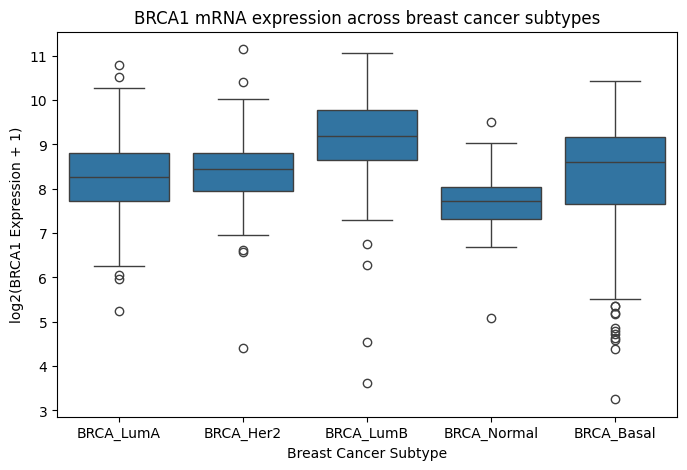

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

merged_df['log2_BRCA1'] = np.log2(merged_df['BRCA1_Expression'] + 1)

plt.figure(figsize=(8,5))
sns.boxplot(data=merged_df, x='SUBTYPE', y='log2_BRCA1')
plt.title('BRCA1 mRNA expression across breast cancer subtypes')
plt.ylabel('log2(BRCA1 Expression + 1)')
plt.xlabel('Breast Cancer Subtype')
plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

lumb_vals = merged_df[merged_df['SUBTYPE'] == 'BRCA_LumB']['log2_BRCA1'].dropna()
luma_vals = merged_df[merged_df['SUBTYPE'] == 'BRCA_LumA']['log2_BRCA1'].dropna()

stat, p_value = mannwhitneyu(lumb_vals, luma_vals)
print(f"P-value comparing LumB vs LumA: {p_value:.2e}")

P-value comparing LumB vs LumA: 1.43e-29


In [ ]:
!pip install lifelines

merged_df[['log2_BRCA1', 'OS_MONTHS', 'OS_STATUS']].head()


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=e1f63e2b50ccb0ccb0e88a9f689150e0c1a2cf055f630c9b63de0ae931a293a6
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lifelines]


,log2_BRCA1,OS_MONTHS,OS_STATUS
0,9.700989,133.050597,0:LIVING
1,8.610604,131.669790,0:LIVING
2,7.653655,48.459743,0:LIVING
3,7.220311,47.604958,0:LIVING
4,8.557445,11.440971,0:LIVING


In [ ]:
surv_df = merged_df[['log2_BRCA1', 'OS_MONTHS', 'OS_STATUS']].dropna().copy()


surv_df['OS_EVENT'] = surv_df['OS_STATUS'].map({'0:LIVING': 0, '1:DECEASED': 1})


median_brca1 = surv_df['log2_BRCA1'].median()
surv_df['BRCA1_Group'] = np.where(surv_df['log2_BRCA1'] > median_brca1, 'High BRCA1', 'Low BRCA1')


surv_df.head()

,log2_BRCA1,OS_MONTHS,OS_STATUS,OS_EVENT,BRCA1_Group
0,9.700989,133.050597,0:LIVING,0,High BRCA1
1,8.610604,131.669790,0:LIVING,0,High BRCA1
2,7.653655,48.459743,0:LIVING,0,Low BRCA1
3,7.220311,47.604958,0:LIVING,0,Low BRCA1
4,8.557445,11.440971,0:LIVING,0,High BRCA1


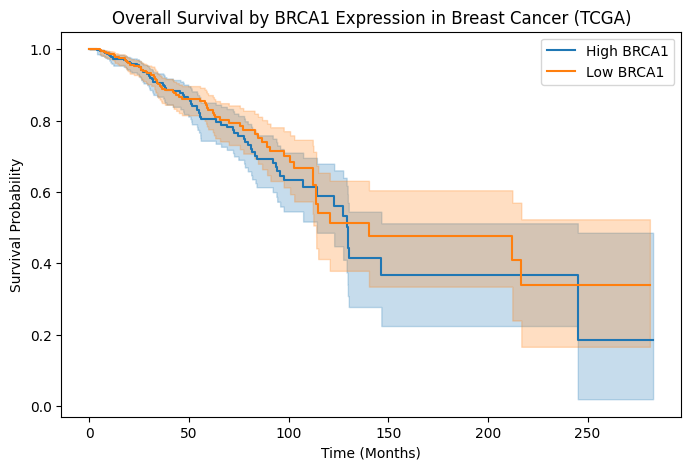

Log-rank test p-value: 0.4329


In [ ]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

high_group = surv_df[surv_df['BRCA1_Group'] == 'High BRCA1']
low_group = surv_df[surv_df['BRCA1_Group'] == 'Low BRCA1']

kmf = KaplanMeierFitter()
plt.figure(figsize=(8,5))

kmf.fit(durations=high_group['OS_MONTHS'], event_observed=high_group['OS_EVENT'], label='High BRCA1')
kmf.plot_survival_function()

kmf.fit(durations=low_group['OS_MONTHS'], event_observed=low_group['OS_EVENT'], label='Low BRCA1')
kmf.plot_survival_function()

plt.title('Overall Survival by BRCA1 Expression in Breast Cancer (TCGA)')
plt.xlabel('Time (Months)')
plt.ylabel('Survival Probability')
plt.show()

results = logrank_test(
    high_group['OS_MONTHS'], low_group['OS_MONTHS'],
    event_observed_A=high_group['OS_EVENT'], event_observed_B=low_group['OS_EVENT']
)
print(f"Log-rank test p-value: {results.p_value:.4f}")





